# Week 1: Object Counting with YOLOv8
Steps: setup, load model, run on images, count per class, annotate.

**Tip:** Runtime > Change runtime type > T4 GPU

In [ ]:
!pip install ultralytics -q

In [ ]:
from ultralytics import YOLO
import cv2, os, glob
from collections import Counter
import matplotlib.pyplot as plt

model = YOLO("yolov8s.pt")   # pretrained on COCO (80 classes)
print(list(model.names.values())[:20], "...")

['person', 'bicycle', 'car', 'motorcycle', 'airplane', 'bus', 'train', 'truck', 'boat', 'traffic light', 'fire hydrant', 'stop sign', 'parking meter', 'bench', 'bird', 'cat', 'dog', 'horse', 'sheep', 'cow'] ...


## Add test images
Upload about 20 permitted images (note their sources). They are saved in `test_images/`.

In [ ]:
from google.colab import files
os.makedirs("test_images", exist_ok=True)
uploaded = files.upload()
for name in uploaded:
    os.replace(name, os.path.join("test_images", name))
print(os.listdir("test_images"))

Saving bang street.webp to bang street.webp
Saving beetles street.webp to beetles street.webp
Saving cali street.webp to cali street.webp
Saving cambodia.jpg to cambodia.jpg
Saving china street.webp to china street.webp
Saving den street.webp to den street.webp
Saving gaza street.webp to gaza street.webp
Saving hong kong street.webp to hong kong street.webp
Saving iceland street.webp to iceland street.webp
Saving ind street.webp to ind street.webp
Saving iran street.webp to iran street.webp
Saving jordan street.webp to jordan street.webp
Saving london street.webp to london street.webp
Saving malay street.webp to malay street.webp
Saving nigeria street.webp to nigeria street.webp
Saving pak street 2.jpg to pak street 2.jpg
Saving pak street.webp to pak street.webp
Saving spain street.jpg to spain street.jpg
Saving sri street.webp to sri street.webp
Saving syria street.jpg to syria street.jpg
['china street.webp', 'test img.avif', 'gaza street.webp', 'cambodia.jpg', 'bang street.webp', '

## Count function
Filters by class names and confidence, returns counts and the annotated image.

In [ ]:
def count_objects(image_path, target_classes=None, conf=0.25):
    class_ids = None
    if target_classes:
        name_to_id = {v: k for k, v in model.names.items()}
        class_ids = [name_to_id[c] for c in target_classes]

    result = model(image_path, conf=conf, classes=class_ids, verbose=False)[0]
    labels = [model.names[int(b.cls)] for b in result.boxes]
    counts = Counter(labels)
    annotated = cv2.cvtColor(result.plot(), cv2.COLOR_BGR2RGB)
    return dict(counts), sum(counts.values()), annotated

## Test on one image

Per-class: {'person': 16} | Total: 16


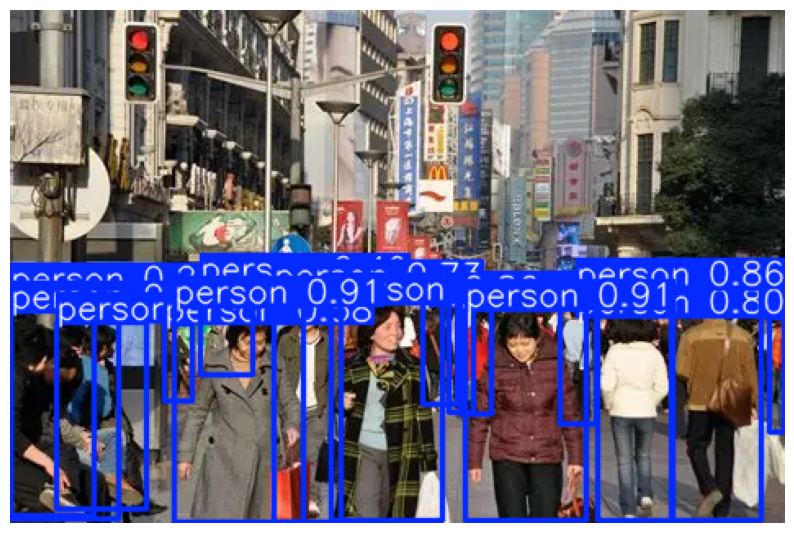

In [ ]:
path = glob.glob("test_images/*")[0]
counts, total, img = count_objects(path, target_classes=["person", "car"], conf=0.25)
print("Per-class:", counts, "| Total:", total)
plt.figure(figsize=(10, 7)); plt.imshow(img); plt.axis("off"); plt.show()

## Run on all test images

In [ ]:
for p in sorted(glob.glob("test_images/*")):
    counts, total, _ = count_objects(p, target_classes=["person", "car"])
    print(os.path.basename(p), "->", counts, "| total:", total)

bang street.webp -> {'car': 7, 'person': 9} | total: 16
beetles street.webp -> {'person': 6, 'car': 7} | total: 13
cali street.webp -> {'person': 7, 'car': 1} | total: 8
cambodia.jpg -> {'person': 13, 'car': 1} | total: 14
china street.webp -> {'person': 16} | total: 16
den street.webp -> {'car': 3, 'person': 5} | total: 8
gaza street.webp -> {'person': 7} | total: 7
hong kong street.webp -> {'person': 11} | total: 11
iceland street.webp -> {'person': 14} | total: 14
ind street.webp -> {'person': 12} | total: 12
iran street.webp -> {'person': 11} | total: 11
jordan street.webp -> {'person': 10, 'car': 6} | total: 16
london street.webp -> {'person': 22} | total: 22
malay street.webp -> {'person': 12} | total: 12
nigeria street.webp -> {'person': 7, 'car': 4} | total: 11
pak street 2.jpg -> {'person': 13} | total: 13
pak street.webp -> {'person': 14} | total: 14
spain street.jpg -> {'person': 18} | total: 18
sri street.webp -> {'person': 11, 'car': 2} | total: 13
syria street.jpg -> {'pe